In [201]:
seed = 42
test_size = 0.15
val_size = 0.15

In [202]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

In [203]:
print(tf.config.list_physical_devices())

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [204]:
data = pd.read_csv("data/creditcard_2023.csv").drop(columns=["id"])
print(data.describe())

                 V1            V2            V3             V4            V5  \
count  5.686300e+05  5.686300e+05  5.686300e+05  568630.000000  5.686300e+05   
mean  -5.118237e-17 -5.118237e-17  1.023647e-16       0.000000  2.559118e-17   
std    1.000001e+00  1.000001e+00  1.000001e+00       1.000001  1.000001e+00   
min   -3.495584e+00 -4.996657e+01 -3.183760e+00      -4.951222 -9.952786e+00   
25%   -5.652859e-01 -4.866777e-01 -6.492987e-01      -0.656020 -2.934955e-01   
50%   -9.363846e-02 -1.358939e-01  3.528579e-04      -0.073762  8.108788e-02   
75%    8.326582e-01  3.435552e-01  6.285380e-01       0.707005  4.397368e-01   
max    2.229046e+00  4.361865e+00  1.412583e+01       3.201536  4.271689e+01   

                 V6             V7            V8             V9           V10  \
count  5.686300e+05  568630.000000  5.686300e+05  568630.000000  5.686300e+05   
mean   2.559118e-17       0.000000  1.279559e-17       0.000000  1.023647e-16   
std    1.000001e+00       1.000001  

In [205]:
x = data.drop(columns=["Class"])
y = data["Class"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=test_size, random_state=seed, stratify=y
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=val_size, random_state=seed, stratify=y_train
)

In [206]:
scaler = RobustScaler()

x_train = pd.DataFrame(
    scaler.fit_transform(x_train), columns=x_train.columns, index=x_train.index
)

x_val = pd.DataFrame(
    scaler.transform(x_val), columns=x_val.columns, index=x_val.index
)

x_test = pd.DataFrame(
    scaler.transform(x_test), columns=x_test.columns, index=x_test.index
)

print(f"There are a total of {data.isna().sum().sum()} missing values in the dataset.")
data.describe()

There are a total of 0 missing values in the dataset.


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,5.686300e+05,5.686300e+05,5.686300e+05,568630.000000,5.686300e+05,5.686300e+05,568630.000000,5.686300e+05,568630.000000,5.686300e+05,...,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,5.686300e+05,568630.000000,568630.0
mean,-5.118237e-17,-5.118237e-17,1.023647e-16,0.000000,2.559118e-17,2.559118e-17,0.000000,1.279559e-17,0.000000,1.023647e-16,...,1.279559e-17,1.599449e-18,5.598072e-18,-2.559118e-17,-4.478457e-17,-6.397796e-18,-2.559118e-17,3.198898e-17,12041.957635,0.5
std,1.000001e+00,1.000001e+00,1.000001e+00,1.000001,1.000001e+00,1.000001e+00,1.000001,1.000001e+00,1.000001,1.000001e+00,...,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,6919.644449,0.5
min,-3.495584e+00,-4.996657e+01,-3.183760e+00,-4.951222,-9.952786e+00,-2.111111e+01,-4.351839,-1.075634e+01,-3.751919,-3.163276e+00,...,-1.938252e+01,-7.734798e+00,-3.029545e+01,-4.067968e+00,-1.361263e+01,-8.226969e+00,-1.049863e+01,-3.903524e+01,50.010000,0.0
25%,-5.652859e-01,-4.866777e-01,-6.492987e-01,-0.656020,-2.934955e-01,-4.458712e-01,-0.283533,-1.922572e-01,-0.568745,-5.901008e-01,...,-1.664408e-01,-4.904892e-01,-2.376289e-01,-6.515801e-01,-5.541485e-01,-6.318948e-01,-3.049607e-01,-2.318783e-01,6054.892500,0.0
50%,-9.363846e-02,-1.358939e-01,3.528579e-04,-0.073762,8.108788e-02,7.871758e-02,0.233366,-1.145242e-01,0.092526,2.626145e-01,...,-3.743065e-02,-2.732881e-02,-5.968903e-02,1.590123e-02,-8.193162e-03,-1.189208e-02,-1.729111e-01,-1.392973e-02,12030.150000,0.5
75%,8.326582e-01,3.435552e-01,6.285380e-01,0.707005,4.397368e-01,4.977881e-01,0.525955,4.729905e-02,0.559262,5.924603e-01,...,1.479787e-01,4.638817e-01,1.557153e-01,7.007374e-01,5.500147e-01,6.728879e-01,3.340230e-01,4.095903e-01,18036.330000,1.0
max,2.229046e+00,4.361865e+00,1.412583e+01,3.201536,4.271689e+01,2.616840e+01,217.873038,5.958040e+00,20.270062,3.172271e+01,...,8.087080e+00,1.263251e+01,3.170763e+01,1.296564e+01,1.462151e+01,5.623285e+00,1.132311e+02,7.725594e+01,24039.930000,1.0


In [220]:
architectures = [
    [16],
    [32, 16],
    [64, 32, 16],
    [128, 64, 32, 16]
]

def run_model(architecture, num_input_features):
    tf.keras.utils.set_random_seed(seed)

    model = Sequential()
    model.add(Input(shape=(num_input_features,)))
    for units in architecture:
        model.add(Dense(units, activation='tanh'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy', 'f1_score', 'recall', 'precision']
    )

    model.fit(
        x_train,
        y_train,
        epochs=25,
        batch_size=2048,
        validation_data=(x_val, y_val),
        verbose=0
    )

    metrics = model.evaluate(x_test, y_test, return_dict=True, verbose=0)
    y_prob = model.predict(x_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    matrix = ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Legitimate", "Fraud"]
    )

    metric_text = "\n".join(
        f"{name}: {value:.3f}" for name, value in metrics.items()
    )
    matrix.ax_.set_title(f"Test metrics\n{metric_text}\narchitecture: {architecture}")
    matrix.figure_.tight_layout()

    return {"architecture": architecture, "metrics": metrics, "confusion_matrix": matrix}

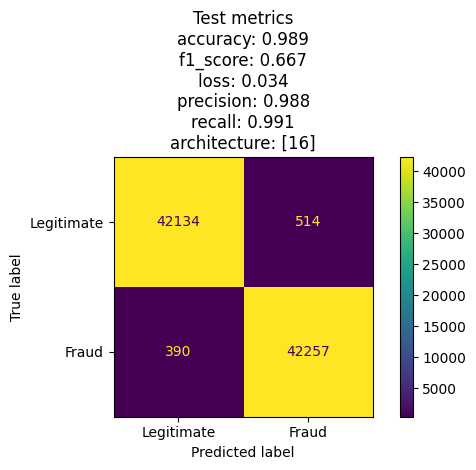

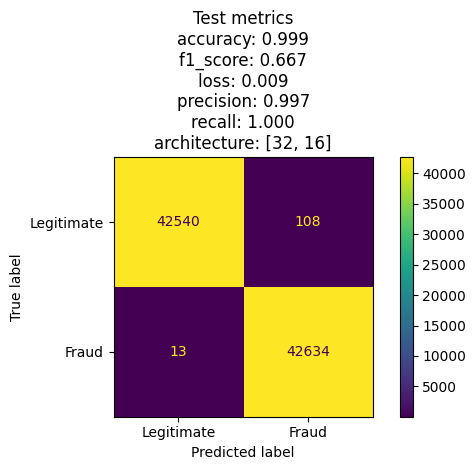

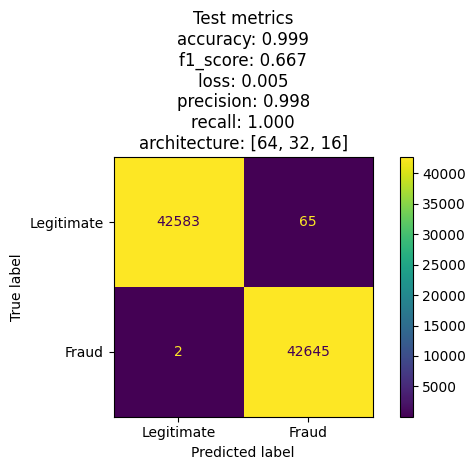

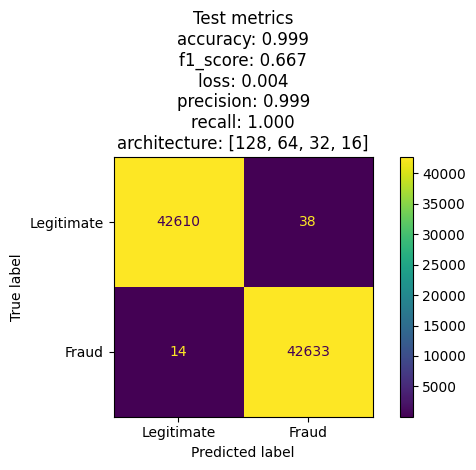

In [221]:
results = [run_model(architecture, num_input_features=29) for architecture in architectures]

In [222]:
for result in results:
    print(result["metrics"])
    print(result["architecture"])
    print()

{'accuracy': 0.9894014596939087, 'f1_score': 0.6667603850364685, 'loss': 0.03391842916607857, 'precision': 0.9879825115203857, 'recall': 0.9908551573753357}
[16]

{'accuracy': 0.9985814094543457, 'f1_score': 0.6666613817214966, 'loss': 0.00885010790079832, 'precision': 0.9974732398986816, 'recall': 0.9996951818466187}
[32, 16]

{'accuracy': 0.9992144703865051, 'f1_score': 0.6666613817214966, 'loss': 0.005143796559423208, 'precision': 0.99847811460495, 'recall': 0.9999530911445618}
[64, 32, 16]

{'accuracy': 0.9993903636932373, 'f1_score': 0.6666613817214966, 'loss': 0.0035221241414546967, 'precision': 0.9991094470024109, 'recall': 0.9996716976165771}
[128, 64, 32, 16]

